In [105]:
import deap
import numpy as np
from deap import algorithms, base, creator, tools
SEED = 42
import random

### Does cooperation emerge and remain stable in an evolving population, and how does the answer depend on the noise level?

In [106]:
NOISE_LEVELS = [0, 0.01, 0.05]
# all combinations of 5 bits
STRATEGIES = [tuple([int(l) for l in format(i, '05b')]) for i in range(32)]
rng = np.random.default_rng(SEED)

In [115]:
# name the classic strategies
CLASSICS = {
    (0, 0, 0, 0, 0): "ALLC",     # always cooperate
    (1, 1, 1, 1, 1): "ALLD",     # always defect   
    (0, 0, 1, 0, 1): "TFT",      # tit for tat, start cooperatively
    (0, 0, 1, 1, 0): "PAVLOV",   # win-stay lose-shift, start C
    (0, 0, 1, 1, 1): "GRIM",     # start cooperative, take any betrayal to heart and spam defect
    (1, 0, 1, 0, 1): "STFT",     # suspicious tit for tat
}

In [ ]:
P1_HEAD_TO_HEAD = np.array([[3, 0], [5, 1]]) # outcomes for p1 in prisoners dilemma

array([[3, 5],
       [0, 1]])

#### Compute expected payoff matrix

In [108]:
# need 3d matrix to store 32x32 matrix with depth 4 to capture payoff in each previous scenario
n = len(STRATEGIES)
PAYOFFS = np.zeros((n, n, 4))
for i in range(n):
    for j in range(n):
        for k in range(4):
            p1_action = STRATEGIES[i][k+1]
            p2_action = STRATEGIES[j][k+1]
            PAYOFFS[i, j, k] = P1_HEAD_TO_HEAD[p1_action, p2_action]


In [109]:
def bits_to_id(bits):
    return int("".join(str(i) for i in bits), 2)

BITS_TO_IDS = { strat : bits_to_id(strat) for strat in STRATEGIES}

In [110]:
BITS_TO_IDS

{(0, 0, 0, 0, 0): 0,
 (0, 0, 0, 0, 1): 1,
 (0, 0, 0, 1, 0): 2,
 (0, 0, 0, 1, 1): 3,
 (0, 0, 1, 0, 0): 4,
 (0, 0, 1, 0, 1): 5,
 (0, 0, 1, 1, 0): 6,
 (0, 0, 1, 1, 1): 7,
 (0, 1, 0, 0, 0): 8,
 (0, 1, 0, 0, 1): 9,
 (0, 1, 0, 1, 0): 10,
 (0, 1, 0, 1, 1): 11,
 (0, 1, 1, 0, 0): 12,
 (0, 1, 1, 0, 1): 13,
 (0, 1, 1, 1, 0): 14,
 (0, 1, 1, 1, 1): 15,
 (1, 0, 0, 0, 0): 16,
 (1, 0, 0, 0, 1): 17,
 (1, 0, 0, 1, 0): 18,
 (1, 0, 0, 1, 1): 19,
 (1, 0, 1, 0, 0): 20,
 (1, 0, 1, 0, 1): 21,
 (1, 0, 1, 1, 0): 22,
 (1, 0, 1, 1, 1): 23,
 (1, 1, 0, 0, 0): 24,
 (1, 1, 0, 0, 1): 25,
 (1, 1, 0, 1, 0): 26,
 (1, 1, 0, 1, 1): 27,
 (1, 1, 1, 0, 0): 28,
 (1, 1, 1, 0, 1): 29,
 (1, 1, 1, 1, 0): 30,
 (1, 1, 1, 1, 1): 31}

### Define evaluation function
Do round robin against all other individuals in population

In [111]:
P2_OUTCOME_MAP = [0, 2, 1, 3] # CD <=> DC from p2 perspective
# first need game function to incorporate noise
def game(last_outcome, p1, p2, noise, rng, h2h):
    if last_outcome is None: # go with first move for strat
        p1_intended = p1[0]
        p2_intended = p2[0]
    else:
        p1_intended = p1[last_outcome + 1]
        p2_intended = p2[P2_OUTCOME_MAP[last_outcome] + 1]
    # players make moves based on last outcome but with p(error) = noise
    p1_move = p1_intended if rng.random() > noise else 1 - p1_intended
    p2_move = p2_intended if rng.random() > noise else 1 - p2_intended
    new_outcome = 2 * p1_move + p2_move # CC = 0, CD = 1, DC = 2, DD = 3
    return h2h[p1_move, p2_move], new_outcome    


In [112]:
N_ROUNDS = 150
# DEAP calls evaluate(ind) only, so opponents/noise live here.
# Each generation, set current_pop[:] = pop before evaluating.
current_pop = []
current_noise = 0.0

def play_match(p1, p2, noise, rng, h2h, n_rounds=N_ROUNDS):
    last_outcome = None
    total = 0.0
    for _ in range(n_rounds):
        payoff, last_outcome = game(last_outcome, p1, p2, noise, rng, h2h)
        total += payoff
    return total / n_rounds

In [113]:
NOISE_PAYOFFS = {0.0 : np.zeros((32, 32)), 0.01: np.zeros((32, 32)), 0.05: np.zeros((32,32))}

for noise in NOISE_LEVELS:
    for i in range(32):
        for j in range(32):
            p1_result = play_match(STRATEGIES[i], STRATEGIES[j], noise, rng, P1_HEAD_TO_HEAD)
            NOISE_PAYOFFS[noise][i][j] = p1_result


def round_robin_evaluate(ind, population=None, noise=None, rng=rng, h2h=P1_HEAD_TO_HEAD, n_rounds=N_ROUNDS):
    """Mean payoff of ind in a round-robin against everyone else in the population."""
    if population is None:
        population = current_pop
    if noise is None:
        noise = current_noise
    competitors = [competitor for competitor in population if competitor is not ind]
    if not competitors:
        return (0.0,)
    ind_index = BITS_TO_IDS[tuple(ind)]
    scores = [NOISE_PAYOFFS[noise][ind_index][BITS_TO_IDS[tuple(competitor)]] for competitor in competitors]
    return (float(np.mean(scores)),)

noise=0  best=3.042  strategy=[1, 1, 0, 1, 1]  stopped after 500 generations
noise=0.01  best=3.030  strategy=[1, 0, 1, 1, 1]  stopped after 500 generations
noise=0.05  best=2.967  strategy=[1, 1, 1, 1, 1]  stopped after 500 generations


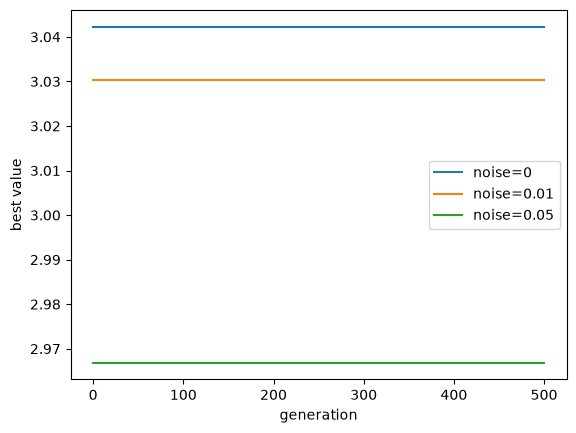

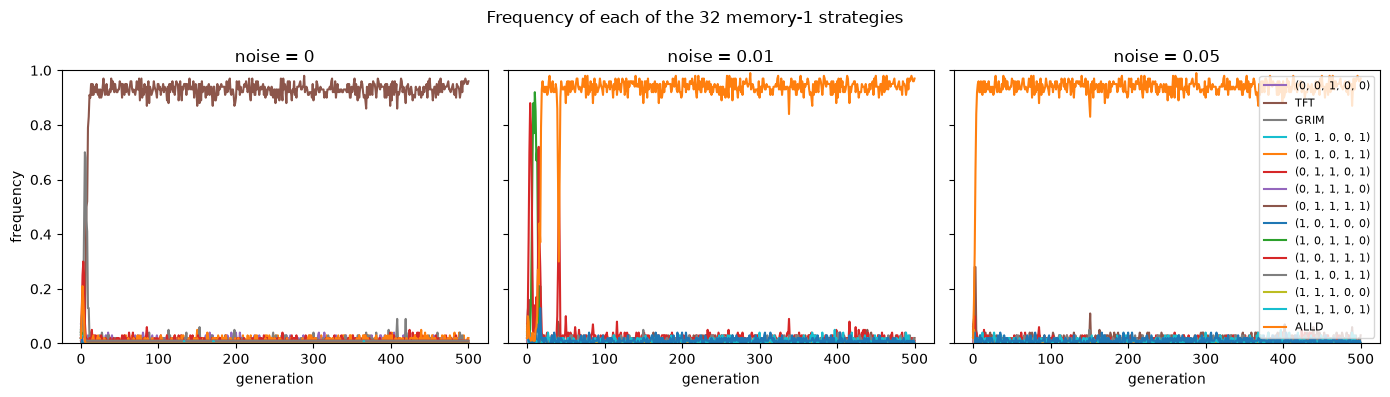

In [119]:
import random
import matplotlib.pyplot as plt
from deap import base, creator, tools, algorithms

try:
    del creator.FitnessMax
    del creator.Individual
except Exception:
    pass

creator.create("FitnessMax", base.Fitness, weights=(1.0,))      # we maximise
creator.create("Individual", list, fitness=creator.FitnessMax)

tb = base.Toolbox()
tb.register("bit", random.randint, 0, 1)
tb.register("individual", tools.initRepeat, creator.Individual, tb.bit, n=5)
tb.register("population", tools.initRepeat, list, tb.individual)
tb.register("evaluate", round_robin_evaluate)
tb.register("mate", tools.cxOnePoint)
tb.register("mutate", tools.mutFlipBit, indpb=0.01)
tb.register("select", tools.selTournament, tournsize=3)


def strategy_frequencies(pop):
    ids = [BITS_TO_IDS[tuple(ind)] for ind in pop]
    return np.bincount(ids, minlength=32) / len(pop)


def run_evolution(noise, seed=SEED):
    global current_noise
    current_noise = noise
    random.seed(seed)
    pop = tb.population(n=100)
    current_pop[:] = pop
    for ind in pop:
        ind.fitness.values = tb.evaluate(ind)

    hof = tools.HallOfFame(2)
    hof.update(pop)
    best, stall, gen = [hof[0].fitness.values[0]], 0, 0
    hist_freq = [strategy_frequencies(pop)]

    while gen < 500: #and stall < 50:
        gen += 1
        offspring = algorithms.varAnd(tb.select(pop, len(pop)), tb, cxpb=0.7, mutpb=1)
        for i, elite in enumerate(hof):
            offspring[i] = tb.clone(elite)
            del offspring[i].fitness.values  # fitness depends on opponents; re-score elites

        current_pop[:] = offspring
        for ind in offspring:
            if not ind.fitness.valid:
                ind.fitness.values = tb.evaluate(ind)
        pop = offspring

        old = hof[0].fitness.values[0]
        hof.update(pop)
        stall = stall + 1 if hof[0].fitness.values[0] <= old else 0
        best.append(hof[0].fitness.values[0])
        hist_freq.append(strategy_frequencies(pop))

    print(
        f"noise={noise}  best={hof[0].fitness.values[0]:.3f}  "
        f"strategy={list(hof[0])}  stopped after {gen} generations"
    )
    return {"best": np.array(best), "freq": np.array(hist_freq), "hof": hof, "n_gen": gen}


results = {noise: run_evolution(noise) for noise in NOISE_LEVELS}

for noise, res in results.items():
    plt.plot(res["best"], label=f"noise={noise}")
plt.xlabel("generation")
plt.ylabel("best value")
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, noise in zip(axes, NOISE_LEVELS):
    freq = results[noise]["freq"]
    for k in range(32):
        series = freq[:, k]
        label = f"{CLASSICS[STRATEGIES[k]] if STRATEGIES[k] in CLASSICS else STRATEGIES[k]}" if series.max() >= 0.05 else None
        ax.plot(series, label=label)
    ax.set_title(f"noise = {noise}")
    ax.set_xlabel("generation")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("frequency")
axes[-1].legend(loc="upper right", fontsize=8)
fig.suptitle("Frequency of each of the 32 memory-1 strategies")
fig.tight_layout()
plt.show()

In [117]:
freq

array([[0.04, 0.01, 0.04, ..., 0.02, 0.03, 0.02],
       [0.  , 0.  , 0.02, ..., 0.02, 0.03, 0.15],
       [0.  , 0.  , 0.  , ..., 0.03, 0.04, 0.33],
       ...,
       [0.  , 0.  , 0.  , ..., 0.01, 0.  , 0.96],
       [0.  , 0.  , 0.  , ..., 0.  , 0.01, 0.96],
       [0.  , 0.  , 0.  , ..., 0.  , 0.  , 0.97]], shape=(501, 32))